# IMS Bearings — Future Work: LSTM and Asymmetric Loss

**Companion file:** `bearings_future_work.py` (same directory as this notebook).

This notebook extends the *existing* IMS bearing workflow rather than reprocessing the raw `.txt` vibration files. It compares **Extra Trees**, **LSTM with MSE**, and **LSTM with asymmetric loss**, using leave-one-test-set-out evaluation. The target is a **0–1 pseudo-health/RUL index**, not actual hours remaining.

### Project folder
```text
ML project/
├── bearings_pipeline.ipynb          # existing feature-extraction notebook
├── bearings_future_work.ipynb       # this notebook
├── bearings_future_work.py          # training and evaluation module
├── bearing_predictor.py            # existing predictors
├── bearing_predictor2.py
├── bearings/                       # NASA IMS files
│   ├── 1st_test/
│   ├── 2nd_test/
│   └── 3rd_test/
└── bearings_out/
    ├── features_raw.pkl            # generated by original notebook
    └── future_work/                # new results go here
```

**First-time setup:** Open your original `bearings_pipeline` notebook and run through its feature cache cell (cell 4) if `bearings_out/features_raw.pkl` does not exist. It is not necessary to re-extract features if that pickle is already present.

## 1. Imports and project paths

In [1]:
# %pip install --upgrade pandas

In [10]:
%matplotlib inline

In [2]:
# Run once, if needed (uncomment):
# %pip install torch numpy pandas scipy scikit-learn matplotlib joblib

from pathlib import Path
import sys
import subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()  # launch Jupyter from your ML project folder
CACHE = ROOT / "bearings_out" / "features_raw.pkl"
OUT = ROOT / "bearings_out" / "lstm"
SCRIPT = ROOT / "lstm_experiments.py"

print("Project:", ROOT)
print("Module found:", SCRIPT.exists())
print("Cached features found:", CACHE.exists())
if not SCRIPT.exists():
    raise FileNotFoundError(f"Put bearings_future_work.py next to this notebook: {SCRIPT}")
if not CACHE.exists():
    raise FileNotFoundError("Run your old bearings_pipeline notebook through cell 4 to generate bearings_out/features_raw.pkl")

Project: C:\Users\Samyuktha K\projects\ML project
Module found: True
Cached features found: True


## 2. Examine the cached features

These are already extracted from NASA IMS vibration snapshots in your previous notebook. No need to download the dataset again.

In [3]:
raw = pd.read_pickle(CACHE)
print("Shape:", raw.shape)
print("Columns:", len(raw.columns))
display(raw[['test','run','bearing','timestamp']].head())
display(raw.groupby(['test','run'], sort=True).size().rename('snapshots').to_frame())

Shape: (8667, 33)
Columns: 33


,test,run,bearing,timestamp
0,1st_test,1st_test_b3,b3,2003-10-22 12:06:24
1,1st_test,1st_test_b3,b3,2003-10-22 12:09:13
2,1st_test,1st_test_b3,b3,2003-10-22 12:14:13
3,1st_test,1st_test_b3,b3,2003-10-22 12:19:13
4,1st_test,1st_test_b3,b3,2003-10-22 12:24:13


snapshots
test     run                   
1st_test 1st_test_b3       2156
         1st_test_b4       2156
2nd_test 2nd_test_b1        984
3rd_test 3rd_test_b3       3371

## 3. Prepare normalized features and pseudo-labels

The module rebuilds the training features from the cached raw features using each run’s **hours 40–70** as a baseline. The target is assigned retrospectively from the end of each run (known only in a run-to-failure research dataset). Actual run end times and degradation onset are **not provided as predictor inputs**.

In [4]:
import bearings_future_work as fw

feat = fw.prepare(raw)
print("Feature columns:", len(fw.COLS))
display(feat.groupby('run')[['t_hours','onset_hours']].max().round(1))
print("Test sets:", sorted(feat['test'].unique()))

Feature columns: 52


,t_hours,onset_hours
run,,
1st_test_b3,345.3,292.6
1st_test_b4,345.3,244.3
2nd_test_b1,163.8,115.3
3rd_test_b3,561.4,548.7


Test sets: ['1st_test', '2nd_test', '3rd_test']


## 4. Visualize reference labels

These labels are engineered targets, **not direct measurements** of bearing health.

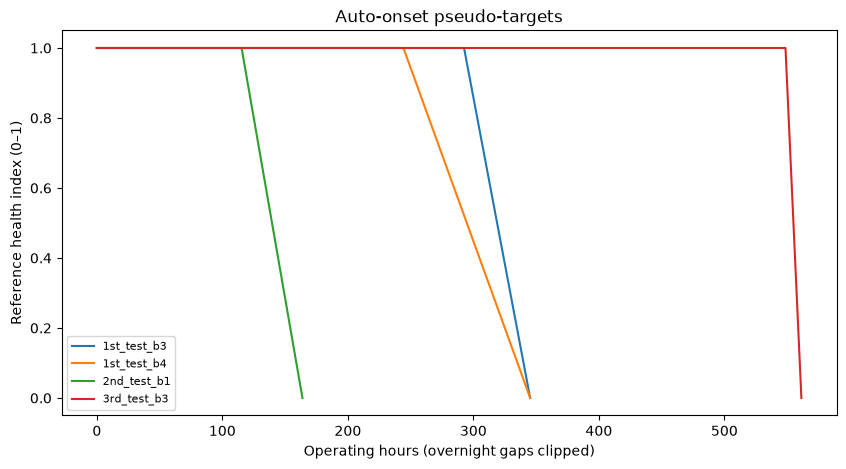

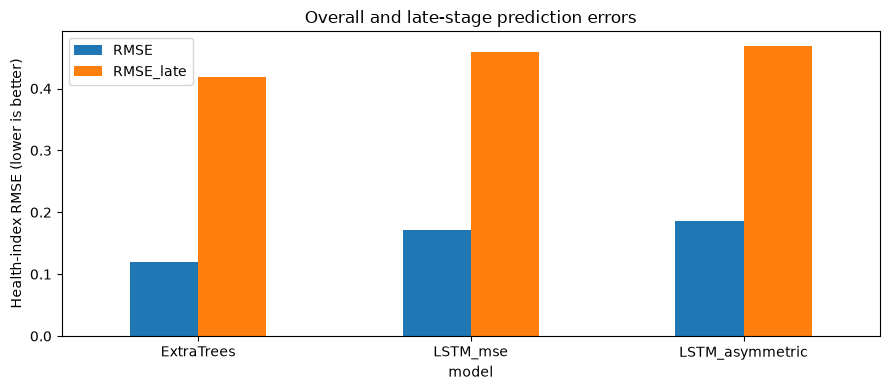

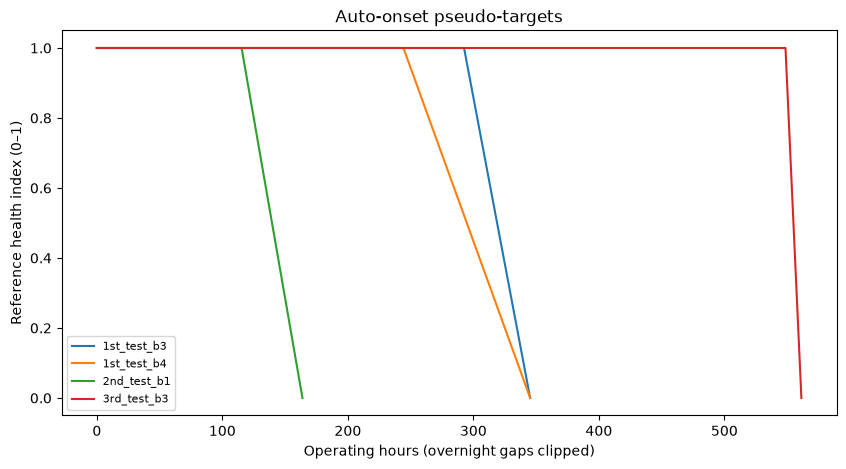

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
for run, g in feat.groupby('run'):
    ax.plot(g['t_hours'], g['target'], label=run)
ax.set(xlabel='Operating hours (overnight gaps clipped)', ylabel='Reference health index (0–1)', title='Auto-onset pseudo-targets')
ax.legend(fontsize=8)
plt.show()

## 5. Train the three models

The script creates a new train/test split for each held-out NASA test set. Fit the standard scaler on **training runs only**. An LSTM observes sequences of 36 snapshots (about six hours at the nominal ten-minute interval); it predicts the health index at the **end** of each window.

Increase `EPOCHS` after a quick smoke test. A full run can take some time, particularly on CPU.

In [6]:
EPOCHS = 20
SEQ_LEN = 36
TRAIN_STRIDE = 3
BATCH_SIZE = 128
DEVICE = 'auto'  # auto, cpu, or cuda

cmd = [sys.executable, str(SCRIPT),
       '--cache', str(CACHE),
       '--out', str(OUT),
       '--epochs', str(EPOCHS),
       '--seq-len', str(SEQ_LEN),
       '--train-stride', str(TRAIN_STRIDE),
       '--batch-size', str(BATCH_SIZE),
       '--device', DEVICE]
print('Executing:', ' '.join(cmd))
# Logs stream into this Jupyter cell; a nonzero exit raises an error.
subprocess.run(cmd, cwd=ROOT, check=True)

Executing: C:\AppData\miniconda\python.exe C:\Users\Samyuktha K\projects\ML project\bearings_future_work.py --cache C:\Users\Samyuktha K\projects\ML project\bearings_out\features_raw.pkl --out C:\Users\Samyuktha K\projects\ML project\bearings_out\future_work --epochs 20 --seq-len 36 --train-stride 3 --batch-size 128 --device auto


CompletedProcess(args=['C:\\AppData\\miniconda\\python.exe', 'C:\\Users\\Samyuktha K\\projects\\ML project\\bearings_future_work.py', '--cache', 'C:\\Users\\Samyuktha K\\projects\\ML project\\bearings_out\\features_raw.pkl', '--out', 'C:\\Users\\Samyuktha K\\projects\\ML project\\bearings_out\\future_work', '--epochs', '20', '--seq-len', '36', '--train-stride', '3', '--batch-size', '128', '--device', 'auto'], returncode=0)

## 6. Compare model performance

A lower RMSE/MAE is better. The `late_overestimate_mean` measures overprediction when reference health is below 0.5. Since the reference target is scaled 0–1, `NRMSE` equals RMSE under **range normalization**; it is included for clarity, not as an independent metric.

In [7]:
summary = pd.read_csv(OUT / 'summary_metrics.csv', index_col=0)
per_run = pd.read_csv(OUT / 'per_run_metrics.csv')
display(summary.round(4))
display(per_run[['held_test','run','model','RMSE','MAE','RMSE_late','late_overestimate_mean','false_alarm_rate']].round(4))

,RMSE,MAE,NRMSE,RMSE_late,late_overestimate_mean,false_alarm_rate
model,,,,,,
ExtraTrees,0.1202,0.0530,0.1202,0.4178,0.3944,0.0701
LSTM_mse,0.1719,0.0741,0.1719,0.4595,0.4017,0.0370
LSTM_asymmetric,0.1854,0.0831,0.1854,0.4689,0.3687,0.0662


,held_test,run,model,RMSE,MAE,RMSE_late,late_overestimate_mean,false_alarm_rate
0,1st_test,1st_test_b3,ExtraTrees,0.1547,0.0516,0.5339,0.5256,0.0000
1,1st_test,1st_test_b3,LSTM_mse,0.2146,0.0791,0.7397,0.7256,0.0000
2,1st_test,1st_test_b3,LSTM_asymmetric,0.2121,0.0756,0.7297,0.7177,0.0000
3,1st_test,1st_test_b4,ExtraTrees,0.0988,0.0531,0.2332,0.1875,0.0000
4,1st_test,1st_test_b4,LSTM_mse,0.0742,0.0375,0.1629,0.1251,0.0000
5,1st_test,1st_test_b4,LSTM_asymmetric,0.0863,0.0397,0.2057,0.0065,0.0000
6,2nd_test,2nd_test_b1,ExtraTrees,0.1424,0.0849,0.1681,0.1435,0.2804
7,2nd_test,2nd_test_b1,LSTM_mse,0.3118,0.1620,0.1779,0.0136,0.1479
8,2nd_test,2nd_test_b1,LSTM_asymmetric,0.3563,0.1998,0.1827,0.0077,0.2649
9,3rd_test,3rd_test_b3,ExtraTrees,0.0848,0.0225,0.7360,0.7210,0.0000


## 7. Plot performance on each held-out run

**1st_test_b3**

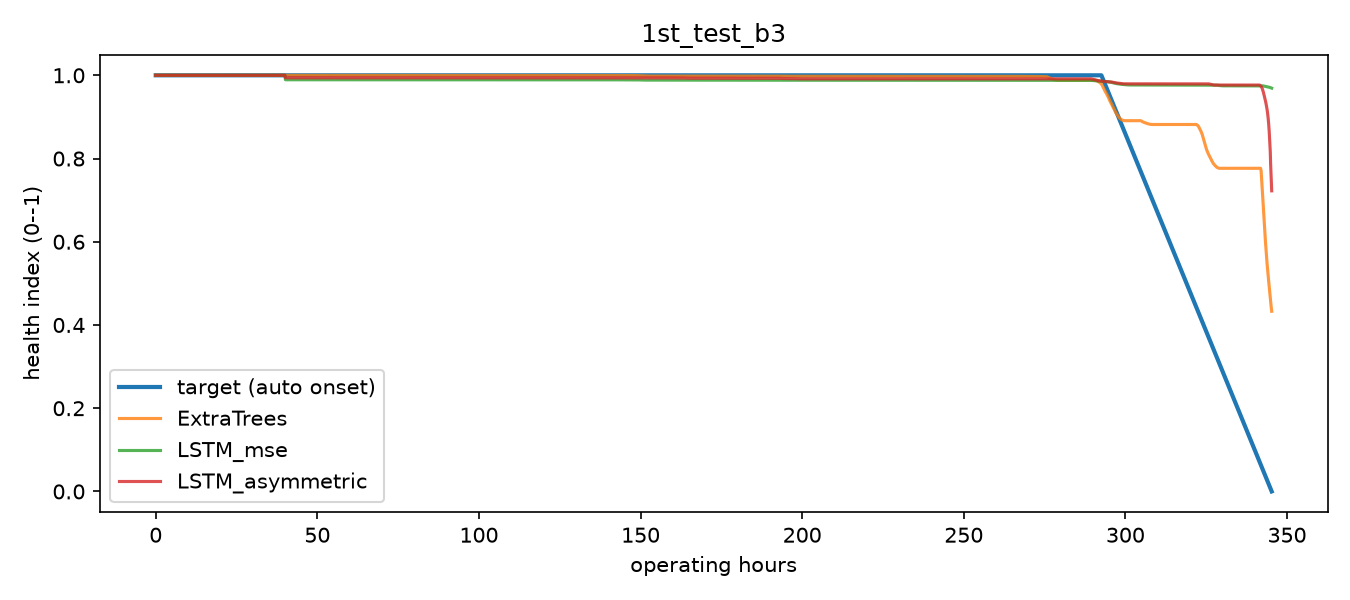

**1st_test_b4**

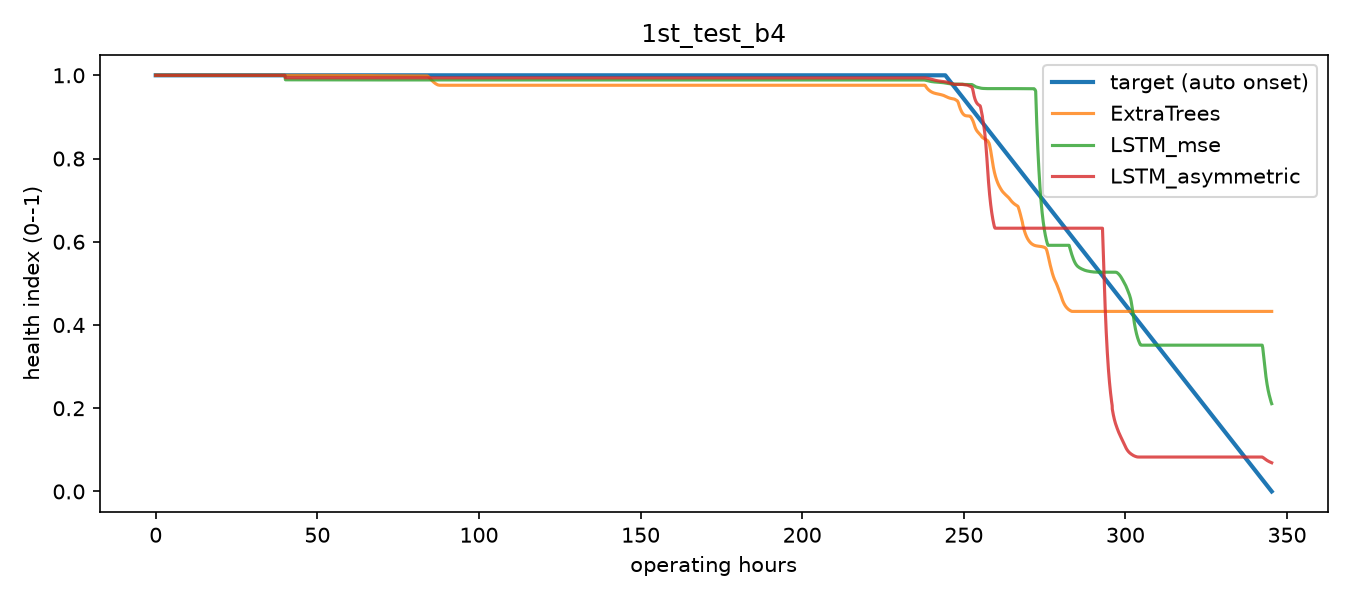

**2nd_test_b1**

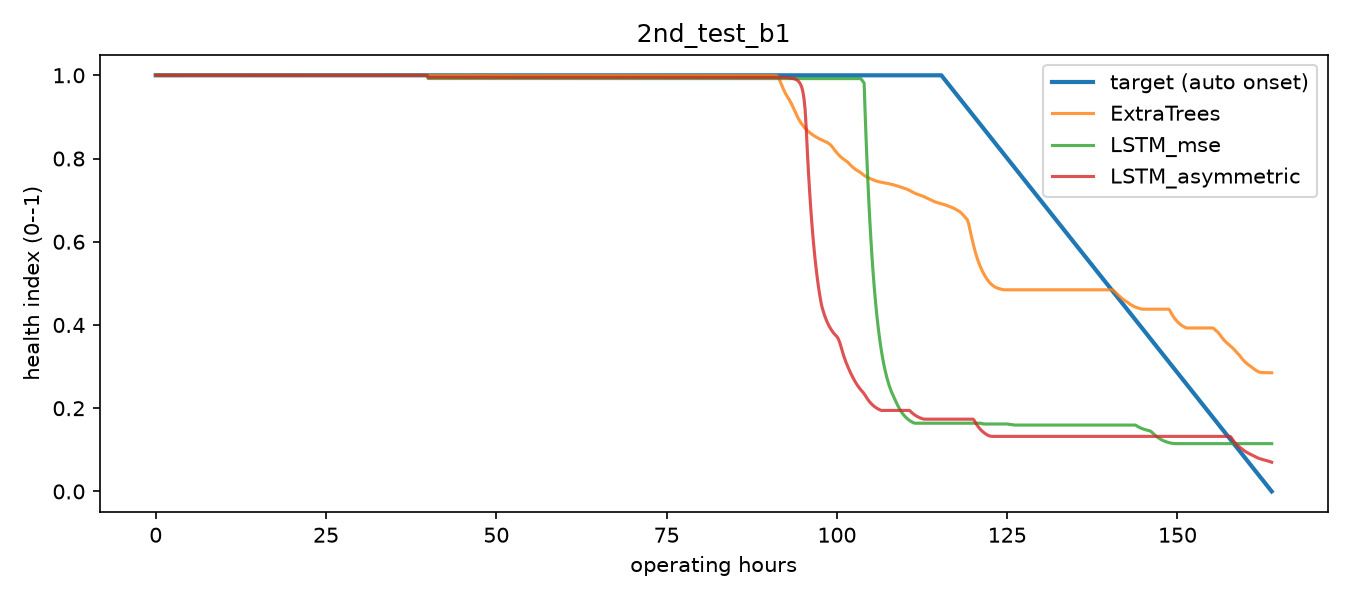

**3rd_test_b3**

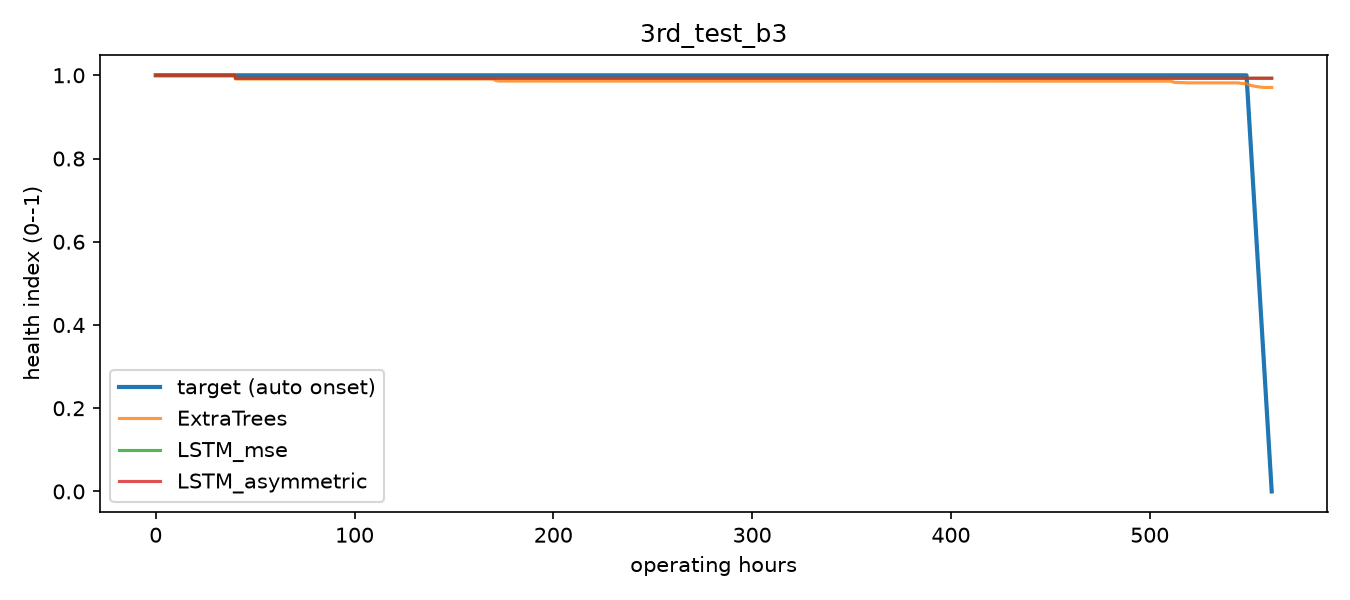

In [8]:
for path in sorted(OUT.glob('*_comparison.png')):
    display(Markdown(f'**{path.stem.replace("_comparison", "")}**'))
    display(Image(filename=str(path)))

## 8. Visual comparison of late-stage errors

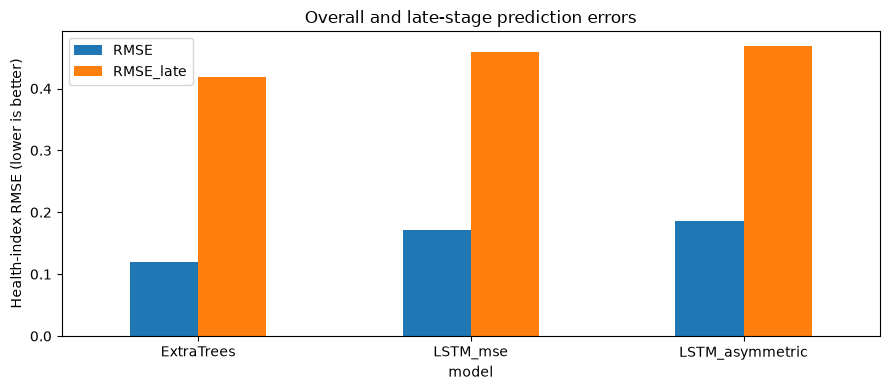

In [12]:
ax = summary[['RMSE','RMSE_late']].plot(kind='bar', figsize=(9,4), rot=0)
ax.set_ylabel('Health-index RMSE (lower is better)')
ax.set_title('Overall and late-stage prediction errors')
plt.tight_layout()
plt.show()

## 9. Interpret the experiment

Use the actual metrics printed above. In your final project, compare whether the LSTM improves on Extra Trees **under the same splits and label definition**. Then test whether asymmetric training reduces late overestimation, and whether it increases false alarms.

**Important cautions**
- The original midsem 0.418 late-stage result is not necessarily directly comparable: your original experiment could use different label/onset or scoring configurations. The `ExtraTrees` row in **this** experiment is the appropriate matched baseline.
- The NASA IMS archive contains a small number of physically distinct run-to-failure tests; individual snapshots are **not** independent test units.
- A ‘false alarm’ calculated before a pseudo-onset on a failing bearing is *not* proof of real-world false-alarm performance on healthy bearings. Continue the separate healthy-bearings check using `bearing_predictor2.py`.
- An LSTM does not provide a validated hour-level RUL estimate; do not describe 0–1 targets as actual remaining hours.

**Next experiment:** Try `SEQ_LEN` = 12, 36, 72 with the same held-out splits. Change only one hyperparameter at a time and document the final model on unseen runs.